# Phân tích bổ sung trên tập train

Kiểm tra độ nhạy của kết quả với các vector feature giống nhau, so sánh hai ngưỡng phân loại và thử tinh chỉnh Random Forest. Các thí nghiệm dùng 9.864 phiên train đã lưu. Kết quả test của [tuần 3](03_evaluation.ipynb) vẫn áp dụng cho cấu hình đã chốt trước đó.

## 1. Đọc train và lập nhóm theo 16 feature

In [1]:
%matplotlib inline
import json
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedGroupKFold, StratifiedKFold, cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

csv = Path("data/online_shoppers_intention.csv")
split = json.loads(Path("data/split_indices.json").read_text(encoding="utf-8"))
if sha256(csv.read_bytes()).hexdigest() != split["csv_sha256"]:
    raise ValueError("CSV không khớp với split đã lưu.")

df = pd.read_csv(csv)
train_indices = split["train_indices"]
test_indices = split["test_indices"]
all_indices = train_indices + test_indices
if (
    len(all_indices) != len(df)
    or split["n_rows"] != len(df)
    or any(type(index) is not int for index in all_indices)
    or set(all_indices) != set(df.index)
):
    raise ValueError("Split phải phủ đủ các dòng và mỗi dòng xuất hiện đúng một lần.")

train = df.iloc[train_indices]
X = train.drop(columns=["Revenue", "PageValues"])
y = train["Revenue"]
groups = X.groupby(list(X.columns), sort=False, dropna=False).ngroup()
repeated_groups = groups.value_counts().gt(1).sum()
print(f"{len(X):,} phiên train · {X.shape[1]} feature · {groups.nunique():,} nhóm")
print(f"{repeated_groups} nhóm có từ hai phiên với cùng vector feature.")

9,864 phiên train · 16 feature · 9,773 nhóm
61 nhóm có từ hai phiên với cùng vector feature.


## 2. So sánh StratifiedKFold và StratifiedGroupKFold

Nhóm được xác định từ feature trước preprocessing. `StratifiedGroupKFold` giữ mỗi nhóm trong cùng một fold validation và cố gắng cân bằng tỷ lệ nhãn. Cả hai mô hình dùng cùng fold trong mỗi cách chia. Cột AP trung bình dùng điểm tính riêng trên từng fold. AP gộp từ dự đoán out-of-fold trả lời câu hỏi khác vì nó xếp hạng phiên từ nhiều mô hình fit riêng.

In [2]:
categories = [
    "Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"
]
numbers = [column for column in X if column not in categories]

def make_pipeline(classifier, scale_numeric=False):
    prep = ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories),
        ("numbers", StandardScaler() if scale_numeric else "passthrough", numbers),
    ])
    return Pipeline([("preprocessing", prep), ("classifier", classifier)])

forest = make_pipeline(RandomForestClassifier(
    n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=1
))
logistic = make_pipeline(LogisticRegression(max_iter=1000), scale_numeric=True)
regular = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y))
grouped = list(StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
).split(X, y, groups))

def fold_ap(probabilities, folds):
    return np.array([average_precision_score(y.iloc[val], probabilities[val]) for _, val in folds])

comparison = []
fold_details = []
for label, folds in [("StratifiedKFold", regular), ("StratifiedGroupKFold", grouped)]:
    for number, (fit, val) in enumerate(folds, 1):
        shared = groups.iloc[val].isin(groups.iloc[fit]).sum()
        if label == "StratifiedGroupKFold":
            assert shared == 0
        fold_details.append({
            "CV": label, "Fold": number, "Số phiên validation": len(val),
            "Tỷ lệ mua": y.iloc[val].mean(), "Số phiên có vector trùng phần fit": shared,
        })
    for name, model in [("Random Forest", forest), ("Logistic Regression", logistic)]:
        scores = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
        ap = fold_ap(scores, folds)
        comparison.append({
            "CV": label, "Mô hình": name, "AP trung bình": ap.mean(), "Độ lệch chuẩn": ap.std(),
        })
        if label == "StratifiedGroupKFold" and name == "Random Forest":
            grouped_forest_oof = scores
            grouped_forest_ap = ap

display(pd.DataFrame(fold_details).round(4))
display(pd.DataFrame(comparison).round(4))

,CV,Fold,Số phiên validation,Tỷ lệ mua,Số phiên có vector trùng phần fit
0,StratifiedKFold,1,1973,0.1546,26
1,StratifiedKFold,2,1973,0.1546,23
2,StratifiedKFold,3,1973,0.1546,21
3,StratifiedKFold,4,1973,0.1551,33
4,StratifiedKFold,5,1972,0.1547,27
5,StratifiedGroupKFold,1,1973,0.1546,0
6,StratifiedGroupKFold,2,1973,0.1551,0
7,StratifiedGroupKFold,3,1973,0.1546,0
8,StratifiedGroupKFold,4,1973,0.1546,0
9,StratifiedGroupKFold,5,1972,0.1547,0


,CV,Mô hình,AP trung bình,Độ lệch chuẩn
0,StratifiedKFold,Random Forest,0.3762,0.0294
1,StratifiedKFold,Logistic Regression,0.3232,0.0196
2,StratifiedGroupKFold,Random Forest,0.3828,0.0203
3,StratifiedGroupKFold,Logistic Regression,0.3251,0.0158


## 3. Precision–Recall và chi phí của ngưỡng

Giữ ngưỡng tuần 3 làm mốc so sánh. Trên xác suất OOF của Random Forest cố định với grouped CV, xét thêm một ngưỡng nhắm tới precision tối thiểu 40%. Đây là mốc minh họa được đặt trước khi chọn ngưỡng. Chọn ngưỡng có recall cao nhất trong các ngưỡng đạt mốc. Khi đồng hạng, lấy ngưỡng cao nhất. Các điểm trên đường PR và số lỗi dưới đây là số liệu mô tả trên chính tập OOF dùng để chọn ngưỡng.

,Phương án,Ngưỡng,Precision,Recall,F1,FP,FN,TP
0,Ngưỡng tuần 3,0.209649,0.322097,0.619921,0.423930,1991,580,946
1,Ưu tiên precision,0.275864,0.401103,0.381389,0.390998,869,944,582


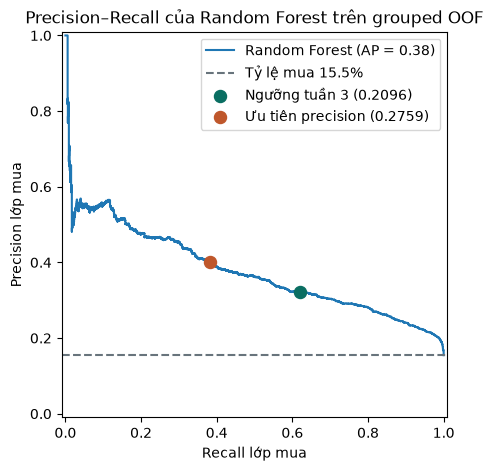

In [3]:
week3_threshold = 0.20964924233624288
precision_floor = 0.40
precision, recall, thresholds = precision_recall_curve(y, grouped_forest_oof)
eligible = np.flatnonzero(precision[:-1] >= precision_floor)
if not len(eligible):
    raise ValueError("Không có ngưỡng dự đoán mua nào đạt precision mục tiêu.")
best = eligible[recall[eligible] == recall[eligible].max()][-1]
higher_precision_threshold = thresholds[best]

threshold_rows = []
for name, threshold in [
    ("Ngưỡng tuần 3", week3_threshold),
    ("Ưu tiên precision", higher_precision_threshold),
]:
    predictions = grouped_forest_oof >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[False, True]).ravel()
    threshold_rows.append({
        "Phương án": name, "Ngưỡng": threshold,
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions),
        "F1": f1_score(y, predictions),
        "FP": fp, "FN": fn, "TP": tp,
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(6))

fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
PrecisionRecallDisplay(
    precision=precision, recall=recall,
    average_precision=average_precision_score(y, grouped_forest_oof),
    ).plot(ax=ax, name="Random Forest")
ax.axhline(y.mean(), linestyle="--", color="#68747C", label=f"Tỷ lệ mua {y.mean():.1%}")
for row, color in zip(threshold_rows, ["#0A6E62", "#BF572B"]):
    ax.scatter(row["Recall"], row["Precision"], s=75, color=color, zorder=3,
               label=f"{row['Phương án']} ({row['Ngưỡng']:.4f})")
ax.set(title="Precision–Recall của Random Forest trên grouped OOF",
       xlabel="Recall lớp mua", ylabel="Precision lớp mua")
ax.legend(loc="upper right")
plt.show()

## 4. Tinh chỉnh Random Forest bằng nested grouped CV

Thử 12 cấu hình kết hợp `max_depth` (8, 12, hoặc không giới hạn), `min_samples_leaf` (5 hoặc 15) và `class_weight` (mặc định hoặc balanced). Mỗi cấu hình có 100 cây. Với mỗi fold ngoài, GridSearchCV chọn cấu hình theo AP trung bình trên 4 fold nhóm ở phần fit. Pipeline được fit lại trên phần fit ngoài rồi chấm trên phần validation ngoài. Dùng đúng các fold ngoài của Random Forest cố định để so sánh.

Sau phép so sánh này, chạy thêm GridSearchCV trên toàn bộ train với 5 fold nhóm để xác định cấu hình ứng viên. Điểm chọn cấu hình từ lần tìm kiếm này có thể lạc quan vì đã so sánh 12 cấu hình trên cùng bộ fold. So sánh mức cải thiện dựa trên các điểm fold ngoài.

In [4]:
grid = {
    "classifier__max_depth": [8, 12, None],
    "classifier__min_samples_leaf": [5, 15],
    "classifier__class_weight": [None, "balanced"],
}

def find_configuration(X_fit, y_fit, fit_groups, cv, refit=True):
    search = GridSearchCV(
        forest, grid, scoring="average_precision", cv=cv,
        refit=refit, n_jobs=1, error_score="raise",
    )
    return search.fit(X_fit, y_fit, groups=fit_groups)

nested_rows = []
for i, (fit, val) in enumerate(grouped, 1):
    inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    search = find_configuration(X.iloc[fit], y.iloc[fit], groups.iloc[fit], inner)
    tuned_scores = search.predict_proba(X.iloc[val])[:, 1]
    ap = average_precision_score(y.iloc[val], tuned_scores)
    nested_rows.append({
        "Fold ngoài": i, "AP cố định": grouped_forest_ap[i-1], "AP tinh chỉnh": ap,
        "Chênh lệch AP": ap - grouped_forest_ap[i-1],
        **{key.removeprefix("classifier__"): value for key, value in search.best_params_.items()},
    })

nested_results = pd.DataFrame(nested_rows)
display(nested_results.round(5))
summary = nested_results[["AP cố định", "AP tinh chỉnh", "Chênh lệch AP"]]
display(pd.DataFrame({"Trung bình": summary.mean(), "Độ lệch chuẩn": summary.std(ddof=0)}).round(5))

final_search = find_configuration(X, y, groups, grouped, refit=False)
ranking = pd.DataFrame(final_search.cv_results_)[[
    "rank_test_score", "param_classifier__max_depth", "param_classifier__min_samples_leaf",
    "param_classifier__class_weight", "mean_test_score", "std_test_score",
]].sort_values("rank_test_score")
display(ranking.rename(columns={
    "rank_test_score": "Hạng", "param_classifier__max_depth": "max_depth",
    "param_classifier__min_samples_leaf": "min_samples_leaf",
    "param_classifier__class_weight": "class_weight",
    "mean_test_score": "AP trung bình", "std_test_score": "Độ lệch chuẩn",
}).round(5))
print("Ứng viên từ tìm kiếm trên toàn bộ train", final_search.best_params_)

,Fold ngoài,AP cố định,AP tinh chỉnh,Chênh lệch AP,class_weight,max_depth,min_samples_leaf
0,1,0.37075,0.35813,-0.01262,balanced,NaN,5
1,2,0.39437,0.39617,0.00180,NaN,NaN,5
2,3,0.39551,0.39982,0.00431,NaN,8.0,5
3,4,0.34889,0.34747,-0.00142,NaN,NaN,5
4,5,0.40431,0.40257,-0.00174,balanced,NaN,5


,Trung bình,Độ lệch chuẩn
AP cố định,0.38277,0.02026
AP tinh chỉnh,0.38083,0.02322
Chênh lệch AP,-0.00193,0.00578


,Hạng,max_depth,min_samples_leaf,class_weight,AP trung bình,Độ lệch chuẩn
4,1,None,5,NaN,0.38332,0.02378
2,2,12,5,NaN,0.38277,0.02026
10,3,None,5,balanced,0.38273,0.02962
5,4,None,15,NaN,0.38174,0.02930
9,5,12,15,balanced,0.38021,0.03129
3,6,12,15,NaN,0.38012,0.02374
11,7,None,15,balanced,0.37957,0.03337
8,8,12,5,balanced,0.37902,0.02753
0,9,8,5,NaN,0.37615,0.02407
1,10,8,15,NaN,0.37450,0.02730


Ứng viên từ tìm kiếm trên toàn bộ train {'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 5}
